# Escalado
Conjunto de datos: iris (incluido en sklearn)
Este conjunto de datos es compacto y perfecto para demostrar técnicas de escalado.

In [1]:
# Importar librerías necesarias
from sklearn.datasets import load_iris
from sklearn.preprocessing import MinMaxScaler, StandardScaler
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Cargar el conjunto de datos
iris = load_iris(as_frame=True)
data = iris.data

In [3]:
# Visualizar las estadísticas iniciales
print("Estadísticas iniciales:")
data.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


Estadísticas iniciales:


In [4]:
# Aplicar MinMaxScaler
minmax_scaler = MinMaxScaler()
data_minmax = pd.DataFrame(minmax_scaler.fit_transform(data), columns=data.columns)

In [5]:
# Aplicar StandardScaler
standard_scaler = StandardScaler()
data_standard = pd.DataFrame(standard_scaler.fit_transform(data), columns=data.columns)

# Ejercicios
Contesta las siguientes preguntas. Para cada pregunta, deberás escribir código que demostrará cómo llegaste al resultado. Crea gráficas en donde veas correcto.

### 1. ¿Qué diferencias encuentras entre las estadísticas originales y las del escalado MinMax?


In [6]:
# Comparar las mismas estadísticas antes y después de MinMax.

estadisticas_originales = data.describe()
estadisticas_minmax = data_minmax.describe()
comparacion = pd.concat(
    {"Original": estadisticas_originales, "MinMax": estadisticas_minmax},
    axis=1,
).swaplevel(0, 1, axis=1).sort_index(axis=1)
display(comparacion.round(4))

print(
    "MinMax transforma cada variable mediante (x - mínimo) / (máximo - mínimo). "
    "En estos datos, todos los mínimos pasan a 0 y los máximos a 1. "
    "La media y los cuartiles se trasladan y se dividen por el rango original; "
    "la desviación estándar solo se divide por ese rango. "
    "El número de observaciones no cambia. Se conservan el orden de los valores "
    "y la forma de cada distribución, pero se pierden las unidades originales. "
    "No se garantiza una media de 0 ni una desviación estándar de 1."
)


petal length (cm)            ... sepal width (cm)          
                 MinMax  Original  ...           MinMax  Original
count          150.0000  150.0000  ...         150.0000  150.0000
mean             0.4675    3.7580  ...           0.4406    3.0573
std              0.2992    1.7653  ...           0.1816    0.4359
min              0.0000    1.0000  ...           0.0000    2.0000
25%              0.1017    1.6000  ...           0.3333    2.8000
50%              0.5678    4.3500  ...           0.4167    3.0000
75%              0.6949    5.1000  ...           0.5417    3.3000
max              1.0000    6.9000  ...           1.0000    4.4000

[8 rows x 8 columns]

MinMax transforma cada variable mediante (x - mínimo) / (máximo - mínimo). En estos datos, todos los mínimos pasan a 0 y los máximos a 1. La media y los cuartiles se trasladan y se dividen por el rango original; la desviación estándar solo se divide por ese rango. El número de observaciones no cambia. Se conservan el orden de los valores y la forma de cada distribución, pero se pierden las unidades originales. No se garantiza una media de 0 ni una desviación estándar de 1.


### 2. Crea una gráfica de la distribución de la variable 'sepal length (cm)' antes y después del escalado.

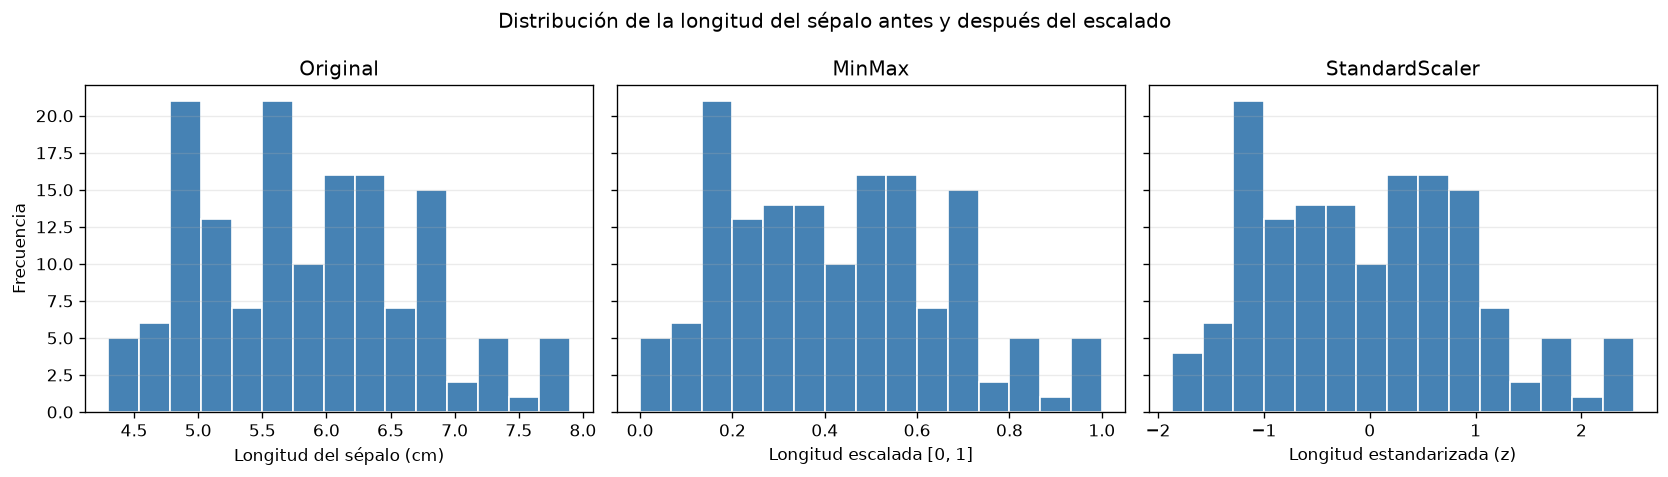

Ambos escalados conservan la forma de la distribución; cambia la escala del eje horizontal.


In [7]:
# Usar intervalos equivalentes para comparar la forma de la distribución.
import numpy as np

variable = "sepal length (cm)"
limites_originales = np.histogram_bin_edges(data[variable], bins=15)
minimo = data[variable].min()
rango = data[variable].max() - minimo
media = data[variable].mean()
desviacion = data[variable].std(ddof=0)

series = [data[variable], data_minmax[variable], data_standard[variable]]
limites = [
    limites_originales,
    (limites_originales - minimo) / rango,
    (limites_originales - media) / desviacion,
]
titulos = ["Original", "MinMax", "StandardScaler"]
etiquetas = ["Longitud del sépalo (cm)", "Longitud escalada [0, 1]", "Longitud estandarizada (z)"]

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, valores, bins, titulo, etiqueta in zip(axes, series, limites, titulos, etiquetas):
    ax.hist(valores, bins=bins, color="steelblue", edgecolor="white")
    ax.set(title=titulo, xlabel=etiqueta)
    ax.grid(axis="y", alpha=0.25)
axes[0].set_ylabel("Frecuencia")
fig.suptitle("Distribución de la longitud del sépalo antes y después del escalado")
fig.tight_layout()
plt.show()

print("Ambos escalados conservan la forma de la distribución; cambia la escala del eje horizontal.")


### 3. Crea una gráfica de dispersión entre 'sepal length (cm)' y 'sepal width (cm)' con los datos escalados por StandardScaler.

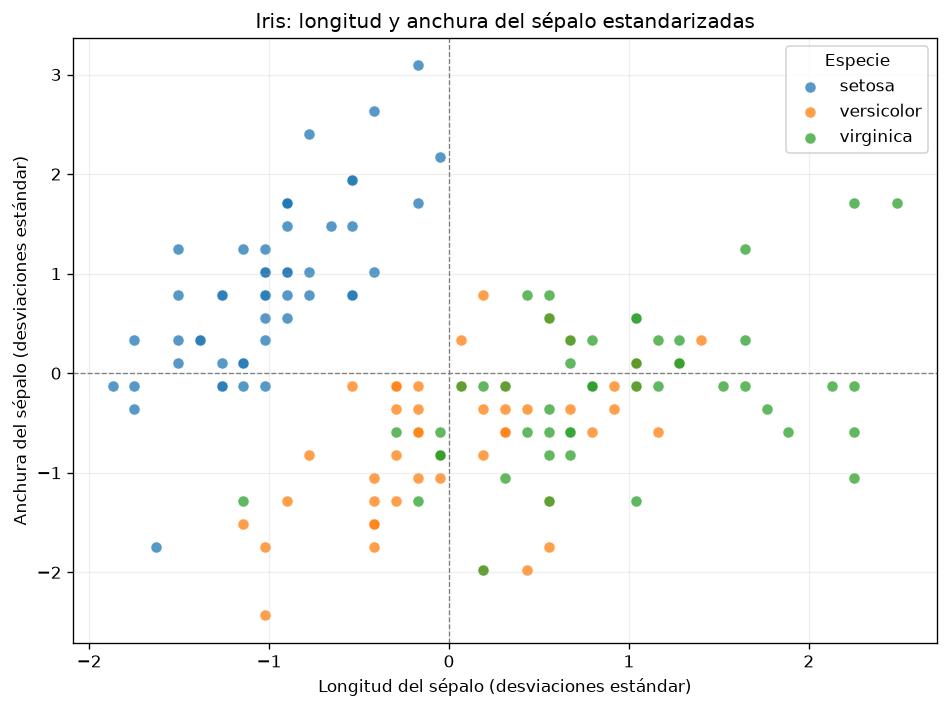

In [8]:
# Las especies solo se usan para colorear, no se incluyen en el escalado.
x = "sepal length (cm)"
y = "sepal width (cm)"
fig, ax = plt.subplots(figsize=(8, 6))
for especie, nombre in enumerate(iris.target_names):
    mascara = iris.target == especie
    ax.scatter(
        data_standard.loc[mascara, x],
        data_standard.loc[mascara, y],
        label=nombre,
        alpha=0.75,
        s=45,
        edgecolors="white",
        linewidths=0.5,
    )
ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)
ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
ax.set(
    title="Iris: longitud y anchura del sépalo estandarizadas",
    xlabel="Longitud del sépalo (desviaciones estándar)",
    ylabel="Anchura del sépalo (desviaciones estándar)",
)
ax.legend(title="Especie")
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()


### 4. ¿Qué técnica de escalado crees que es más adecuada para este conjunto de datos? ¿Por qué?

In [9]:
# Comparar la dispersión que cada técnica asigna a las cuatro variables.
# ddof=0 coincide con la desviación poblacional usada por StandardScaler.
resumen = pd.DataFrame({
    "Rango original": data.max() - data.min(),
    "Desv. original": data.std(ddof=0),
    "Media MinMax": data_minmax.mean(),
    "Desv. MinMax": data_minmax.std(ddof=0),
    "Media StandardScaler": data_standard.mean(),
    "Desv. StandardScaler": data_standard.std(ddof=0),
})
display(resumen.round(4))

print(
    "Elegiría StandardScaler como punto de partida para modelos sensibles a la "
    "escala, como SVM, KNN o PCA: las cuatro variables de Iris tienen dispersiones "
    "distintas y, tras estandarizar, todas tienen media aproximadamente 0 y "
    "desviación estándar poblacional 1. Así, las variables con mayor dispersión "
    "original no dominan únicamente por su escala. MinMax iguala los rangos, "
    "pero no las desviaciones estándar; es útil si se necesita trabajar en [0, 1]. "
    "Ninguna técnica es universalmente mejor y ambas son sensibles a valores "
    "atípicos. StandardScaler tampoco convierte una distribución en normal. "
    "Para árboles de decisión generalmente no hace falta escalar.\n\n"
    "Aquí se escala el conjunto completo para explorar los datos. En una tarea "
    "predictiva se debe ajustar el escalador solo con los datos de entrenamiento, "
    "preferiblemente dentro de un Pipeline, y elegir la técnica mediante "
    "validación cruzada para evitar fuga de información."
)


,Rango original,Desv. original,Media MinMax,Desv. MinMax,Media StandardScaler,Desv. StandardScaler
sepal length (cm),3.6,0.8253,0.4287,0.2293,-0.0,1.0
sepal width (cm),2.4,0.4344,0.4406,0.1810,-0.0,1.0
petal length (cm),5.9,1.7594,0.4675,0.2982,-0.0,1.0
petal width (cm),2.4,0.7597,0.4581,0.3165,-0.0,1.0


Elegiría StandardScaler como punto de partida para modelos sensibles a la escala, como SVM, KNN o PCA: las cuatro variables de Iris tienen dispersiones distintas y, tras estandarizar, todas tienen media aproximadamente 0 y desviación estándar poblacional 1. Así, las variables con mayor dispersión original no dominan únicamente por su escala. MinMax iguala los rangos, pero no las desviaciones estándar; es útil si se necesita trabajar en [0, 1]. Ninguna técnica es universalmente mejor y ambas son sensibles a valores atípicos. StandardScaler tampoco convierte una distribución en normal. Para árboles de decisión generalmente no hace falta escalar.

Aquí se escala el conjunto completo para explorar los datos. En una tarea predictiva se debe ajustar el escalador solo con los datos de entrenamiento, preferiblemente dentro de un Pipeline, y elegir la técnica mediante validación cruzada para evitar fuga de información.
